# E2 — Consistência temporal das predições (TC-IoU / TC-Dice)

**Pergunta:** a consistência temporal no treino (MT + Temporal) deixa as predições mais **estáveis quadro a
quadro** do que o supervisionado (SUP) e o Mean Teacher (MT)? Dice e HD95 só olham os frames rotulados, que
são isolados e esparsos (≈4 por vídeo). Por isso, não medem estabilidade. Aqui usamos **todos** os frames dos
vídeos de teste, rotulados ou não.

O cálculo pesado (forward de todos os runs em todos os frames, mais Farneback ida e volta) está em
`scripts/e2_temporal.py`, e as definições estão em `src/temporal_consistency.py`. Este notebook só lê os
parquets de `<runs>/temporal/`.

```bash
python scripts/e2_temporal.py            # runs de logs/e2 -> logs/e2/temporal (INCA + UNM; retomável)
```

## 0. A métrica

Para cada par de frames consecutivos $(t, t+1)$:

$$
\mathrm{TC\text{-}IoU}_t=\operatorname{IoU}\!\left(W(P_t,F_{t\to t+1}),\,P_{t+1}\right),\qquad
\mathrm{TC\text{-}Dice}_t=\operatorname{Dice}\!\left(W(P_t,F_{t\to t+1}),\,P_{t+1}\right)
$$

- $P$ é a máscara prevista (argmax), pelo **caminho de avaliação** do método (o teacher EMA nos MT). É o
  mesmo que gera o Dice reportado.
- $F_{t\to t+1}$ é o **mesmo fluxo do treino**: Farneback com o pré-processamento `vfss`, parâmetros do DTC-TRUS
  e mediana 3. Os parâmetros são lidos do `config.yaml` de um run `mt-temporal-*`.
- $W$ é a função `warp` do treino, na convenção `dtc_trus`: no grid de $t+1$, amostra $P_t$ em
  $x - F_{t\to t+1}(x)$ (bilinear, limiar 0,5). O vizinho é $t$ e o centro é $t+1$, exatamente o transporte
  da perda temporal.
- **Casos-limite:** se as duas máscaras estão vazias, o par vale NaN e sai da média (contado em
  `both_empty`). Se só uma está vazia, vale 0.
- **Agregação:** média dos pares **por vídeo**, depois média dos vídeos **por paciente** (cada vídeo pesa
  igual), depois média ± dp entre pacientes. Um vídeo de 256 frames não pesa mais que um de 40. Os testes
  são **pareados por paciente**: teste INCA com 23 pacientes; UNM com 35 vídeos, cada um um "paciente".

Variantes, todas no grid de $t+1$:

| coluna | o que é |
|---|---|
| `tc_iou_mnoc` | IoU ponderada por $M_{noc}=\exp(-\alpha\,|I_{t+1}-W(I_t)|)$, o peso de confiança do treino ($\alpha\approx13{,}3$) |
| `tc_iou_fb` | IoU só nos pixels que passam no teste forward-backward (Sundaram et al., 2010) |
| `tc_iou_identity` | fluxo zero: sobreposição crua de $P_t$ e $P_{t+1}$ (referência, §4) |
| `tc_iou_p10` | p10 da TC dentro do vídeo (depois média por paciente): capta quedas pontuais (*flicker*) que a média esconde |

> **Ressalva (circularidade).** O MT temporal foi treinado para concordar sob **este mesmo** Farneback.
> Parte de um ganho em TC pode, portanto, ser aderência ao próprio objetivo de treino, e não estabilidade
> "verdadeira". Como todos os métodos são medidos sob o mesmo fluxo, os erros do fluxo são de modo comum
> na diferença pareada. Mesmo assim, ler TC **junto** com Dice: uma predição que muda pouco (ou que
> encolhe) também ganha TC.

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

In [2]:
import json
import os
import sys
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src").is_dir())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision.transforms as T
from IPython.display import Markdown, Video, display
from omegaconf import OmegaConf
from PIL import Image
from scipy.stats import kendalltau, wilcoxon
from torchvision.utils import flow_to_image

from src.data.optical_flow import compute_flow, warp
from src.evaluation import aggregate_per_class, table_to_markdown
from src.temporal_consistency import (
    aggregate_video_patient, auroc_from_counts, load_packed_masks, pair_confidence,
    paired_patient_differences, reliability_from_counts, transport_masks,
)

# Runs: o E2 final (com augmentation). Enquanto `logs/e2/temporal` não existir, cai nos runs arquivados SEM
# augmentation -- os números então NÃO são os do artigo; servem para validar a análise.
RUNS_ROOT = ROOT / "logs/e2"
if not (RUNS_ROOT / "temporal/pairs.parquet").exists():
    RUNS_ROOT = ROOT / "logs/_arquivo/e2-sem-aug"
    print(f"[aviso] logs/e2/temporal ainda não existe: usando {RUNS_ROOT.relative_to(ROOT)} (runs SEM augmentation).")
TC_DIR = RUNS_ROOT / "temporal"
FIG_DIR = TC_DIR / "figuras"
FIG_DIR.mkdir(parents=True, exist_ok=True)

TEMPORAL = ["mt-temporal-prev", "mt-temporal-bi", "mt-temporal-prev3"]
MAIN_METHODS = ["supervised", "meanteacher", *TEMPORAL]
EXTRA_METHODS = ["fixmatch", "dtc-trus"]          # calculados, fora das figuras principais
LABELS = {"supervised": "SUP", "meanteacher": "MT", "mt-temporal-prev": "MT+T (t−1)",
          "mt-temporal-bi": "MT+T (t±1)", "mt-temporal-prev3": "MT+T (t−3)",
          "fixmatch": "FixMatch", "dtc-trus": "DTC-TRUS"}
FOCUS = "mt-temporal-bi"                          # variante temporal destacada no qualitativo
COMPARISONS = ([("meanteacher", "supervised")] + [(m, "supervised") for m in TEMPORAL]
               + [(m, "meanteacher") for m in TEMPORAL])
EVAL_SETS = {"inca_test": "Teste INCA", "unm": "UNM"}
N_BOOT = 5000

# Cores (paleta de referência validada): identidade dos métodos vem da POSIÇÃO no eixo; a cor só marca papel.
INK, MUTED, GRID = "#0b0b0b", "#8a8984", "#e4e3df"
C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "font.size": 10, "axes.titlesize": 11, "figure.dpi": 110})

[aviso] logs/e2/temporal ainda não existe: usando logs/_arquivo/e2-sem-aug (runs SEM augmentation).


## 1. Dados

In [3]:
settings = json.loads((TC_DIR / "settings.json").read_text())
pairs = pd.read_parquet(TC_DIR / "pairs.parquet")
flowq = pd.read_parquet(TC_DIR / "flow_quality.parquet")
gt_pairs = pd.read_parquet(TC_DIR / "gt_pairs.parquet")
conf_counts = pd.read_parquet(TC_DIR / "confidence_counts.parquet")
for table in (pairs, flowq, gt_pairs, conf_counts):
    if "paciente_id" in table:
        table["paciente_id"] = table.paciente_id.astype(str)

results = pd.read_csv(RUNS_ROOT / "results_per_sample.csv")
results = results[(results["class"] == "FG") & results.run_id.isin(settings["runs"])].copy()
results["paciente_id"] = results.paciente_id.astype(str)

RUN_OF = pairs.drop_duplicates("method").set_index("method").run_id.to_dict()
METHODS = [m for m in MAIN_METHODS + EXTRA_METHODS if m in RUN_OF]
MAIN = [m for m in MAIN_METHODS if m in RUN_OF]

print("Fluxo:", settings["flow_kwargs"], "|", settings["warp_convention"], f"| alpha={settings['noc_alpha']:.2f}")
print("Runs:", ", ".join(LABELS.get(m, m) for m in METHODS))
if settings.get("max_frames_per_video") or settings.get("max_videos"):
    print("[aviso] cálculo PARCIAL:", {k: settings[k] for k in ("max_frames_per_video", "max_videos")})
pairs.groupby("eval_set").apply(lambda g: pd.Series({
    "pacientes": g.paciente_id.nunique(), "vídeos": g.video_id.nunique(),
    "pares por run": len(g) // g.run_id.nunique(),
    "pares com as 2 máscaras vazias (%)": 100 * g.both_empty.mean(),
}), include_groups=False)

Fluxo: {'method': 'farneback', 'preprocess': 'vfss', 'farneback_params': None, 'median_ksize': 3} | dtc_trus | alpha=13.28
Runs: SUP, MT, MT+T (t−1), MT+T (t±1), MT+T (t−3), FixMatch


,pacientes,vídeos,pares por run,pares com as 2 máscaras vazias (%)
eval_set,,,,
inca_test,23.0,56.0,10646.0,0.000000
unm,35.0,35.0,133101.0,1.201093


## 2. Tabela: Dice, HD95 e TC nos mesmos pacientes

- Dice e HD95 vêm dos frames **rotulados** (`results_per_sample.csv`): média dos frames por paciente, a
  convenção do artigo (`aggregate_per_class`). HD95 está em pixels a 256×256; estrutura não detectada
  recebe a diagonal da imagem.
- TC vem de **todos** os pares, agregada vídeo → paciente.
- `±` é o desvio entre pacientes (uma seed). O `assert` garante que toda célula da tabela usa o mesmo
  conjunto de pacientes.

In [4]:
TC_METRICS = ["tc_iou", "tc_dice", "tc_iou_mnoc", "tc_iou_fb", "tc_iou_identity", "tc_dice_mnoc", "tc_dice_fb"]
KEYS = ["eval_set", "method", "paciente_id"]

tc_patient = aggregate_video_patient(pairs, TC_METRICS, by=["eval_set", "method"])
tc_p10 = (aggregate_video_patient(pairs, ["tc_iou"], by=["eval_set", "method"], video_stat=0.1)
          .rename(columns={"tc_iou": "tc_iou_p10"})[KEYS + ["tc_iou_p10"]])
acc_patient = aggregate_per_class(results, group_columns=KEYS)[KEYS + ["dice", "hd95"]]
per_patient = (acc_patient.merge(tc_patient, on=KEYS, how="outer").merge(tc_p10, on=KEYS, how="outer"))

for eval_set, group in per_patient.groupby("eval_set"):
    incomplete = group[group[["dice", "hd95", "tc_iou"]].isna().any(axis=1)]
    assert incomplete.empty, f"{eval_set}: paciente sem Dice/HD95 ou sem TC:\n{incomplete[KEYS]}"
    sets = group.groupby("method").paciente_id.apply(frozenset)
    assert sets.nunique() == 1, f"{eval_set}: conjuntos de pacientes diferem entre métodos"
    print(f"{EVAL_SETS[eval_set]}: {len(next(iter(sets)))} pacientes, os mesmos em todas as métricas e métodos")

Teste INCA: 23 pacientes, os mesmos em todas as métricas e métodos
UNM: 35 pacientes, os mesmos em todas as métricas e métodos


In [5]:
COLUMNS = {"dice": "Dice ↑", "hd95": "HD95 (px) ↓", "tc_iou": "TC-IoU ↑", "tc_dice": "TC-Dice ↑",
           "tc_iou_p10": "TC-IoU p10 ↑", "tc_iou_mnoc": "TC-IoU·M_noc ↑", "tc_iou_fb": "TC-IoU FB ↑"}

summary = (per_patient.groupby(["eval_set", "method"])[list(COLUMNS)].agg(["mean", "std"]))
summary.columns = [f"{m}_{s}" for m, s in summary.columns]
summary["n_pacientes"] = per_patient.groupby(["eval_set", "method"]).paciente_id.nunique()
summary = summary.reset_index()
summary = summary[summary.method.isin(METHODS)]
summary["_order"] = summary.method.map({m: i for i, m in enumerate(METHODS)})
summary = summary.sort_values(["eval_set", "_order"]).drop(columns="_order")
summary.to_csv(TC_DIR / "tabela_tc.csv", index=False)

def fmt(row, metric, digits):
    return f"{row[f'{metric}_mean']:.{digits}f} ± {row[f'{metric}_std']:.{digits}f}"

pretty = pd.DataFrame({
    "conjunto": summary.eval_set.map(EVAL_SETS), "método": summary.method.map(LABELS),
    **{label: summary.apply(fmt, axis=1, metric=metric, digits=2 if metric == "hd95" else 3)
       for metric, label in COLUMNS.items()},
    "n": summary.n_pacientes,
})
(TC_DIR / "tabela_tc.md").write_text(pretty.to_markdown(index=False))
pretty

,conjunto,método,Dice ↑,HD95 (px) ↓,TC-IoU ↑,TC-Dice ↑,TC-IoU p10 ↑,TC-IoU·M_noc ↑,TC-IoU FB ↑,n
5,Teste INCA,SUP,0.867 ± 0.049,5.89 ± 4.20,0.934 ± 0.023,0.965 ± 0.013,0.899 ± 0.038,0.934 ± 0.023,0.934 ± 0.023,23
1,Teste INCA,MT,0.876 ± 0.040,5.08 ± 3.00,0.946 ± 0.020,0.972 ± 0.011,0.913 ± 0.036,0.946 ± 0.020,0.946 ± 0.020,23
3,Teste INCA,MT+T (t−1),0.872 ± 0.046,4.81 ± 3.73,0.946 ± 0.021,0.972 ± 0.011,0.915 ± 0.034,0.946 ± 0.020,0.946 ± 0.021,23
2,Teste INCA,MT+T (t±1),0.877 ± 0.042,4.75 ± 2.77,0.947 ± 0.020,0.972 ± 0.011,0.917 ± 0.032,0.947 ± 0.020,0.947 ± 0.020,23
4,Teste INCA,MT+T (t−3),0.876 ± 0.040,4.67 ± 2.77,0.943 ± 0.023,0.970 ± 0.013,0.910 ± 0.039,0.943 ± 0.023,0.943 ± 0.023,23
0,Teste INCA,FixMatch,0.870 ± 0.038,5.49 ± 3.25,0.940 ± 0.022,0.969 ± 0.012,0.909 ± 0.035,0.940 ± 0.022,0.940 ± 0.022,23
11,UNM,SUP,0.792 ± 0.059,33.80 ± 32.01,0.742 ± 0.087,0.831 ± 0.067,0.480 ± 0.200,0.742 ± 0.087,0.742 ± 0.087,35
7,UNM,MT,0.809 ± 0.065,16.29 ± 26.68,0.787 ± 0.082,0.859 ± 0.063,0.526 ± 0.230,0.787 ± 0.083,0.787 ± 0.082,35
9,UNM,MT+T (t−1),0.823 ± 0.049,5.83 ± 4.45,0.808 ± 0.077,0.865 ± 0.067,0.516 ± 0.302,0.808 ± 0.077,0.808 ± 0.077,35
8,UNM,MT+T (t±1),0.819 ± 0.046,10.46 ± 14.48,0.805 ± 0.074,0.868 ± 0.062,0.536 ± 0.265,0.805 ± 0.074,0.805 ± 0.074,35


### Diferenças pareadas por paciente

Para cada comparação $a-b$: média da diferença por paciente, IC95% bootstrap (reamostrando pacientes),
fração de pacientes em que $a$ é melhor, e Wilcoxon pareado com Holm entre as comparações da mesma
métrica e do mesmo conjunto. No HD95, **negativo é melhor**.

In [6]:
DIFF_METRICS = ["dice", "hd95", "tc_iou", "tc_dice", "tc_iou_p10", "tc_iou_mnoc", "tc_iou_fb"]
comparisons = [(a, b) for a, b in COMPARISONS if a in RUN_OF and b in RUN_OF]
diffs = pd.concat([
    paired_patient_differences(group, metric, comparisons, n_boot=N_BOOT).assign(eval_set=eval_set)
    for eval_set, group in per_patient.groupby("eval_set") for metric in DIFF_METRICS
], ignore_index=True)
diffs["comparação"] = diffs.a.map(LABELS) + " − " + diffs.b.map(LABELS)
diffs.to_csv(TC_DIR / "diferencas_pareadas.csv", index=False)

def cell(row):
    star = "*" if row.p_holm < 0.05 else ""
    digits = 2 if row.metric == "hd95" else 3
    return (f"{row.mean_diff:+.{digits}f} [{row.ci_lo:+.{digits}f}, {row.ci_hi:+.{digits}f}] "
            f"p={row.p_holm:.3f}{star}")

diff_table = (diffs.assign(valor=diffs.apply(cell, axis=1))
              .pivot_table(index=["eval_set", "comparação"], columns="metric", values="valor", aggfunc="first", sort=False)
              [DIFF_METRICS])
diff_table

metric                                                  dice  \
eval_set  comparação                                           
inca_test MT − SUP          +0.009 [+0.003, +0.016] p=0.045*   
          MT+T (t−1) − SUP   +0.005 [-0.000, +0.011] p=0.180   
          MT+T (t±1) − SUP  +0.010 [+0.004, +0.016] p=0.004*   
          MT+T (t−3) − SUP   +0.009 [+0.003, +0.016] p=0.056   
          MT+T (t−1) − MT    -0.004 [-0.009, +0.002] p=0.427   
          MT+T (t±1) − MT    +0.001 [-0.004, +0.005] p=1.000   
          MT+T (t−3) − MT    +0.000 [-0.003, +0.004] p=1.000   
unm       MT − SUP          +0.016 [+0.008, +0.025] p=0.002*   
          MT+T (t−1) − SUP  +0.030 [+0.018, +0.045] p=0.000*   
          MT+T (t±1) − SUP  +0.026 [+0.016, +0.038] p=0.000*   
          MT+T (t−3) − SUP  +0.017 [+0.008, +0.028] p=0.002*   
          MT+T (t−1) − MT    +0.014 [+0.000, +0.029] p=0.461   
          MT+T (t±1) − MT    +0.010 [-0.001, +0.023] p=0.588   
          MT+T (t−3) − MT    +0.000 [-0.007, +0.009] p=0.461   

metric                                                  hd95  \
eval_set  comparação                                           
inca_test MT − SUP              -0.81 [-1.64, -0.17] p=0.263   
          MT+T (t−1) − SUP      -1.08 [-2.33, +0.00] p=0.263   
          MT+T (t±1) − SUP      -1.14 [-2.16, -0.33] p=0.069   
          MT+T (t−3) − SUP      -1.22 [-2.32, -0.35] p=0.263   
          MT+T (t−1) − MT       -0.27 [-1.16, +0.69] p=0.263   
          MT+T (t±1) − MT       -0.33 [-0.86, +0.04] p=0.263   
          MT+T (t−3) − MT       -0.41 [-1.10, +0.11] p=0.284   
unm       MT − SUP           -17.52 [-26.53, -9.69] p=0.000*   
          MT+T (t−1) − SUP  -27.97 [-39.08, -17.91] p=0.000*   
          MT+T (t±1) − SUP  -23.34 [-32.65, -15.11] p=0.000*   
          MT+T (t−3) − SUP   -17.63 [-27.14, -9.62] p=0.000*   
          MT+T (t−1) − MT    -10.45 [-19.47, -3.25] p=0.030*   
          MT+T (t±1) − MT      -5.82 [-10.41, -2.07] p=0.061   
          MT+T (t−3) − MT       -0.11 [-5.96, +5.11] p=0.481   

metric                                                tc_iou  \
eval_set  comparação                                           
inca_test MT − SUP          +0.012 [+0.010, +0.014] p=0.000*   
          MT+T (t−1) − SUP  +0.012 [+0.010, +0.014] p=0.000*   
          MT+T (t±1) − SUP  +0.013 [+0.011, +0.015] p=0.000*   
          MT+T (t−3) − SUP  +0.009 [+0.007, +0.011] p=0.000*   
          MT+T (t−1) − MT    +0.000 [-0.001, +0.002] p=0.315   
          MT+T (t±1) − MT    +0.001 [-0.000, +0.002] p=0.196   
          MT+T (t−3) − MT   -0.003 [-0.004, -0.001] p=0.002*   
unm       MT − SUP          +0.045 [+0.035, +0.054] p=0.000*   
          MT+T (t−1) − SUP  +0.066 [+0.053, +0.080] p=0.000*   
          MT+T (t±1) − SUP  +0.063 [+0.054, +0.073] p=0.000*   
          MT+T (t−3) − SUP  +0.026 [+0.018, +0.035] p=0.000*   
          MT+T (t−1) − MT   +0.021 [+0.008, +0.035] p=0.003*   
          MT+T (t±1) − MT   +0.018 [+0.010, +0.028] p=0.000*   
          MT+T (t−3) − MT   -0.019 [-0.028, -0.010] p=0.000*   

metric                                               tc_dice  \
eval_set  comparação                                           
inca_test MT − SUP          +0.006 [+0.005, +0.008] p=0.000*   
          MT+T (t−1) − SUP  +0.007 [+0.005, +0.008] p=0.000*   
          MT+T (t±1) − SUP  +0.007 [+0.006, +0.008] p=0.000*   
          MT+T (t−3) − SUP  +0.005 [+0.004, +0.006] p=0.000*   
          MT+T (t−1) − MT    +0.000 [-0.000, +0.001] p=0.360   
          MT+T (t±1) − MT    +0.001 [-0.000, +0.001] p=0.196   
          MT+T (t−3) − MT   -0.002 [-0.002, -0.001] p=0.002*   
unm       MT − SUP          +0.029 [+0.021, +0.036] p=0.000*   
          MT+T (t−1) − SUP  +0.034 [+0.024, +0.046] p=0.000*   
          MT+T (t±1) − SUP  +0.037 [+0.031, +0.045] p=0.000*   
          MT+T (t−3) − SUP   +0.008 [-0.000, +0.017] p=0.243   
          MT+T (t−1) − MT    +0.006 [-0.005, +0.017] p=0.368   
          MT+T (t±1) − MT    

## 3. Distribuição de TC-IoU por paciente e diferenças pareadas

À esquerda, um ponto por paciente. As linhas cinza ligam o **mesmo paciente** entre os métodos: é a
variação entre pacientes que o teste pareado remove. À direita, a diferença pareada por paciente
(pontos), com média e IC95% bootstrap. O tracejado em 0 é "sem diferença".

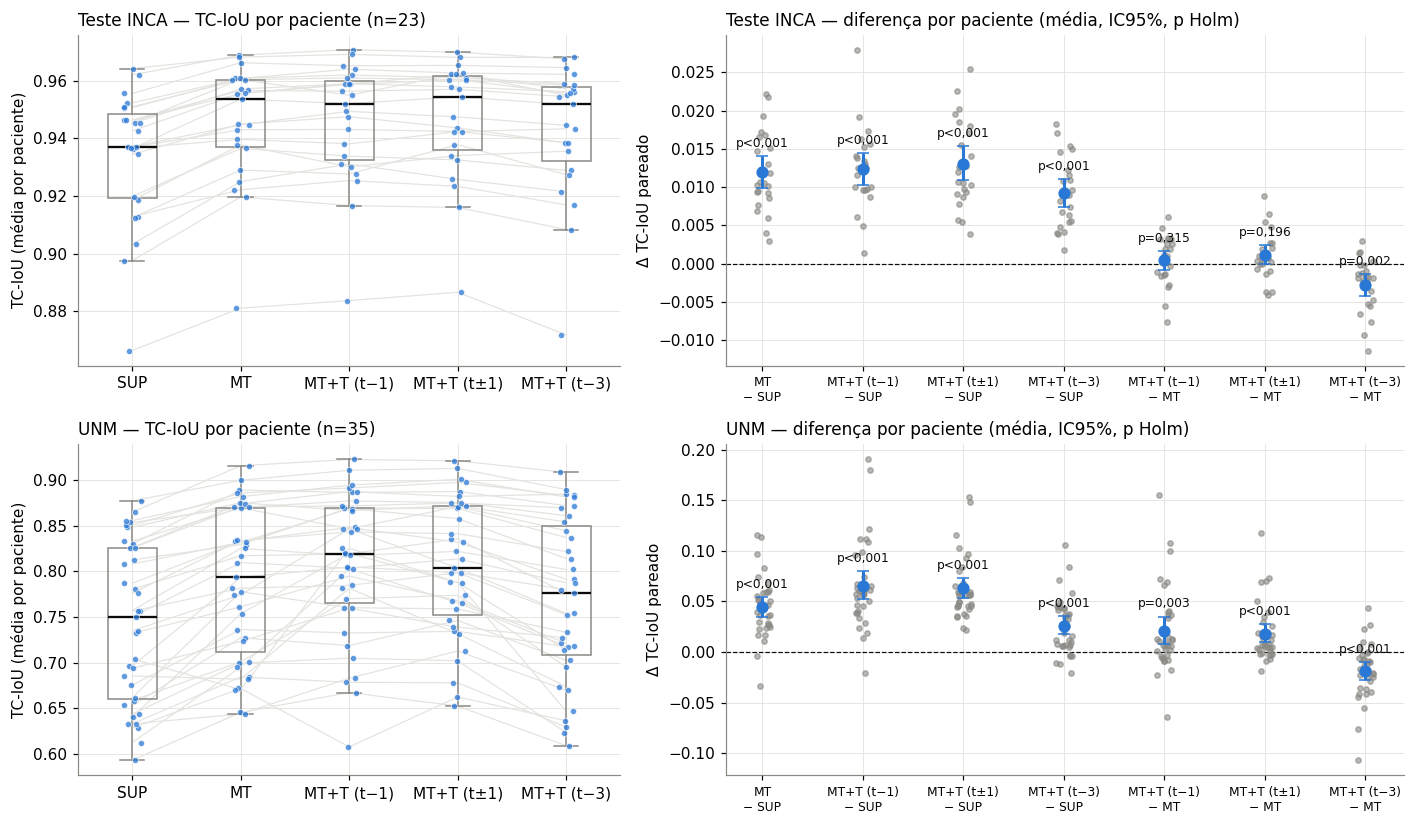

In [7]:
def jitter(n, width=0.08, seed=0):
    return np.random.default_rng(seed).uniform(-width, width, n)


def plot_distribution(metric="tc_iou", label="TC-IoU", comparisons=comparisons):
    sets = [s for s in EVAL_SETS if s in per_patient.eval_set.unique()]
    fig, axes = plt.subplots(len(sets), 2, figsize=(13, 3.8 * len(sets)), squeeze=False,
                             gridspec_kw={"width_ratios": [1, 1.25]})
    for row, eval_set in enumerate(sets):
        data = per_patient[(per_patient.eval_set == eval_set) & per_patient.method.isin(MAIN)]
        wide = data.pivot_table(index="paciente_id", columns="method", values=metric)[MAIN]
        ax = axes[row, 0]
        xs = np.arange(len(MAIN))
        for _, values in wide.iterrows():
            ax.plot(xs, values.values, color=GRID, lw=0.8, zorder=1)
        for i, method in enumerate(MAIN):
            values = wide[method].dropna().values
            ax.boxplot(values, positions=[i], widths=0.45, showfliers=False, patch_artist=True,
                       boxprops=dict(facecolor="none", edgecolor=MUTED), medianprops=dict(color=INK, lw=1.5),
                       whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED), zorder=2)
            ax.scatter(i + jitter(len(values), seed=i), values, s=16, color=C1, alpha=0.75,
                       edgecolor="white", linewidth=0.5, zorder=3)
        ax.set_xticks(xs, [LABELS[m] for m in MAIN])
        ax.set_ylabel(f"{label} (média por paciente)")
        ax.set_title(f"{EVAL_SETS[eval_set]} — {label} por paciente (n={len(wide)})", loc="left")

        ax = axes[row, 1]
        table = diffs[(diffs.eval_set == eval_set) & (diffs.metric == metric)]
        names = []
        for i, (a, b) in enumerate(comparisons):
            d = (wide.get(a) - wide.get(b)).dropna().values if a in wide and b in wide else np.array([])
            r = table[(table.a == a) & (table.b == b)]
            if not len(d) or r.empty:
                continue
            r = r.iloc[0]
            ax.scatter(i + jitter(len(d), seed=10 + i), d, s=12, color=MUTED, alpha=0.6, zorder=2)
            ax.errorbar(i, r.mean_diff, yerr=[[r.mean_diff - r.ci_lo], [r.ci_hi - r.mean_diff]], fmt="o",
                        color=C1, ms=7, lw=2, capsize=4, zorder=3)
            ax.annotate("p<0,001" if r.p_holm < 0.001 else f"p={r.p_holm:.3f}".replace(".", ","), (i, r.ci_hi), textcoords="offset points", xytext=(0, 6),
                        ha="center", fontsize=8, color=INK)
            names.append((i, f"{LABELS[a]}\n− {LABELS[b]}"))
        ax.axhline(0, color=INK, lw=0.8, ls="--", zorder=1)
        ax.set_xticks([i for i, _ in names], [n for _, n in names], fontsize=8)
        ax.set_ylabel(f"Δ {label} pareado")
        ax.set_title(f"{EVAL_SETS[eval_set]} — diferença por paciente (média, IC95%, p Holm)", loc="left")
    fig.tight_layout()
    return fig


fig = plot_distribution("tc_iou", "TC-IoU")
fig.savefig(FIG_DIR / "tc_iou_por_paciente.png", dpi=200, bbox_inches="tight")
fig.savefig(FIG_DIR / "tc_iou_por_paciente.pdf", bbox_inches="tight")

Mesma figura para o **p10** da TC no vídeo. Ele reage a quedas pontuais (*flicker*): um método pode ter TC
média alta e ainda "piscar" em poucos frames.

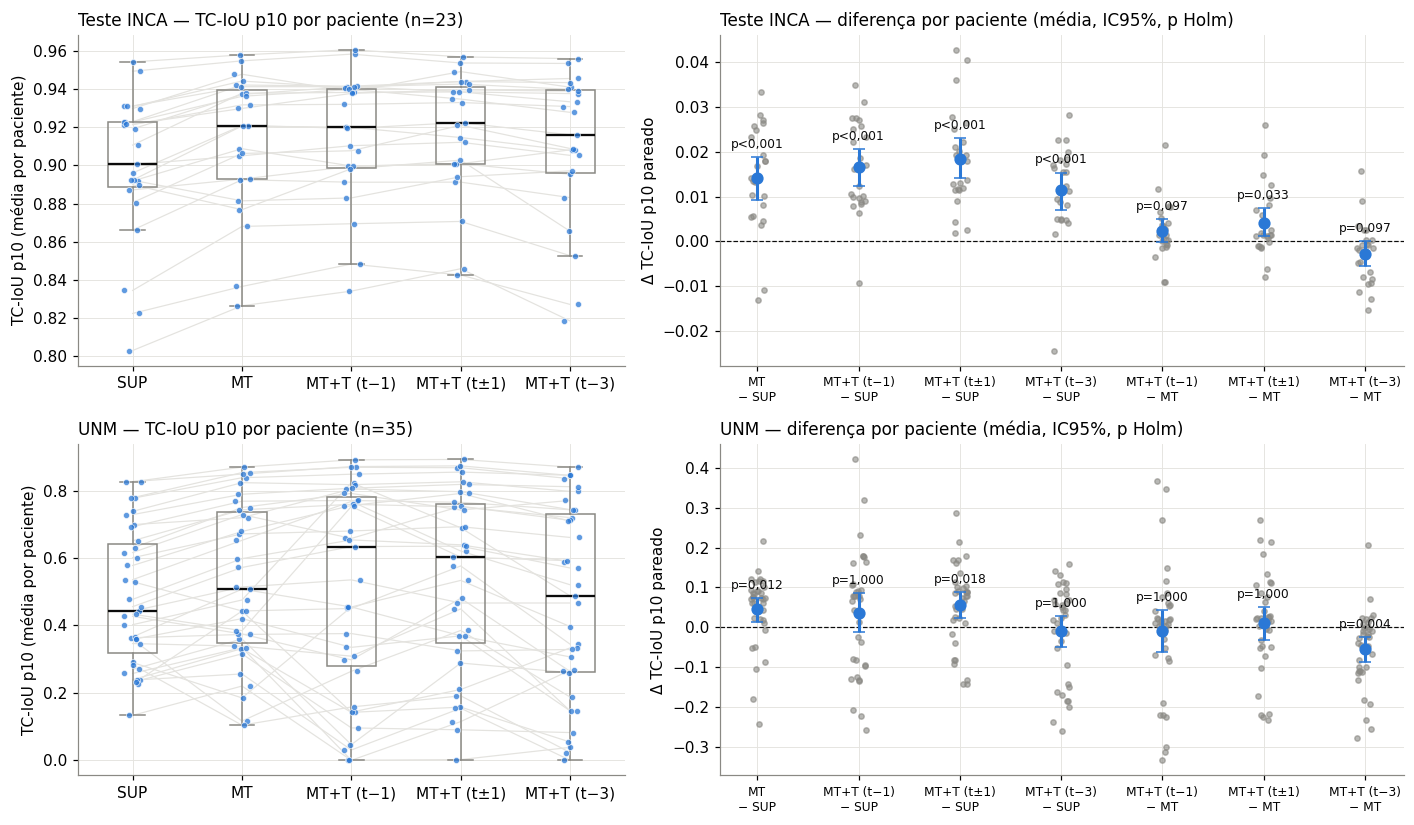

In [8]:
fig = plot_distribution("tc_iou_p10", "TC-IoU p10")
fig.savefig(FIG_DIR / "tc_iou_p10_por_paciente.png", dpi=200, bbox_inches="tight")

## 4. Qualitativo: 5 frames consecutivos

Para não escolher a janela a dedo, ela sai de uma **regra**, aplicada a todas as janelas de 5 frames do
teste INCA:

- `max_diff`: maior $\sum|TC_{FOCUS}-TC_{SUP}|$ nos 4 pares da janela, ou seja, onde os métodos mais
  divergem em estabilidade;
- `typical`: a janela com a TC média do SUP mais próxima da mediana, ou seja, um trecho comum;
- `WINDOW = (video_id, frame_inicial)` fixa uma janela à mão.

Em cada célula, o contorno **azul** é $P_t$ e o **laranja tracejado** é $W(P_{t-1})$, a predição anterior
transportada pelo fluxo. A TC do par é a sobreposição dos dois. As máscaras vêm de
`temporal/masks/inca_test/` (gravadas pelo script).

In [9]:
WINDOW_RULE = "max_diff"    # max_diff | typical
WINDOW = None               # ou (video_id, frame_inicial)
WINDOW_LEN = 5

first_run_dir = Path(next(iter(settings["runs"].values()))).parents[1]
data_params = OmegaConf.load(first_run_dir / "config.yaml").data.params.shared_dataset_params
DATASET_PATH, SIZE = Path(data_params.dataset_path), int(data_params.size)
FRAMES_DIR = (pd.read_csv(DATASET_PATH / "inca-video-frame-dataset.csv").drop_duplicates("video_id")
              .set_index("video_id").image_path.map(lambda p: DATASET_PATH / os.path.dirname(p)).to_dict())
_resize = T.Resize((SIZE, SIZE))


def photo(video_id, frame_id):
    """Imagem [H,W] em [0,1], igual à foto do fluxo no treino (pixel/255 + Resize do dataset)."""
    raw = T.PILToTensor()(Image.open(FRAMES_DIR[int(video_id)] / f"{int(frame_id)}.png").convert("L"))
    return _resize(raw.float() / 255.0).clamp(0, 1)[0].numpy()


_mask_cache = {}
def masks_of(method, video_id):
    key = (method, int(video_id))
    if key not in _mask_cache:
        ids, masks = load_packed_masks(TC_DIR / "masks/inca_test" / RUN_OF[method] / f"v{int(video_id)}.npz")
        _mask_cache[key] = dict(zip(ids.tolist(), masks))
    return _mask_cache[key]


def flow_fw(video_id, t):
    """F_{t->t+1}, como no script (sampling flow da convenção dtc_trus)."""
    kw = settings["flow_kwargs"]
    return torch.from_numpy(compute_flow(photo(video_id, t), photo(video_id, t + 1), method=kw["method"],
                                         preprocess=kw["preprocess"], farneback_params=kw["farneback_params"],
                                         median_ksize=kw["median_ksize"]))[None]


inca = pairs[pairs.eval_set == "inca_test"]
tc_wide = inca.pivot_table(index=["video_id", "frame_t"], columns="method", values="tc_iou")
rows = []
for video_id, g in tc_wide.groupby(level="video_id"):
    g = g.droplevel(0).sort_index()
    for start in g.index[: max(len(g) - (WINDOW_LEN - 2), 0)]:
        w = g.loc[start: start + WINDOW_LEN - 2]
        if len(w) == WINDOW_LEN - 1:
            rows.append({"video_id": video_id, "start": int(start),
                         "diff": (w[FOCUS] - w["supervised"]).abs().sum(), "sup": w["supervised"].mean()})
windows = pd.DataFrame(rows)
if WINDOW is not None:
    video_sel, start_sel = WINDOW
elif WINDOW_RULE == "max_diff":
    best = windows.loc[windows["diff"].idxmax()]
    video_sel, start_sel = int(best.video_id), int(best.start)
else:
    best = windows.loc[(windows.sup - windows.sup.median()).abs().idxmin()]
    video_sel, start_sel = int(best.video_id), int(best.start)
print(f"janela: vídeo {video_sel}, frames {start_sel}..{start_sel + WINDOW_LEN - 1} ({WINDOW_RULE if WINDOW is None else 'manual'})")

janela: vídeo 19, frames 93..97 (max_diff)


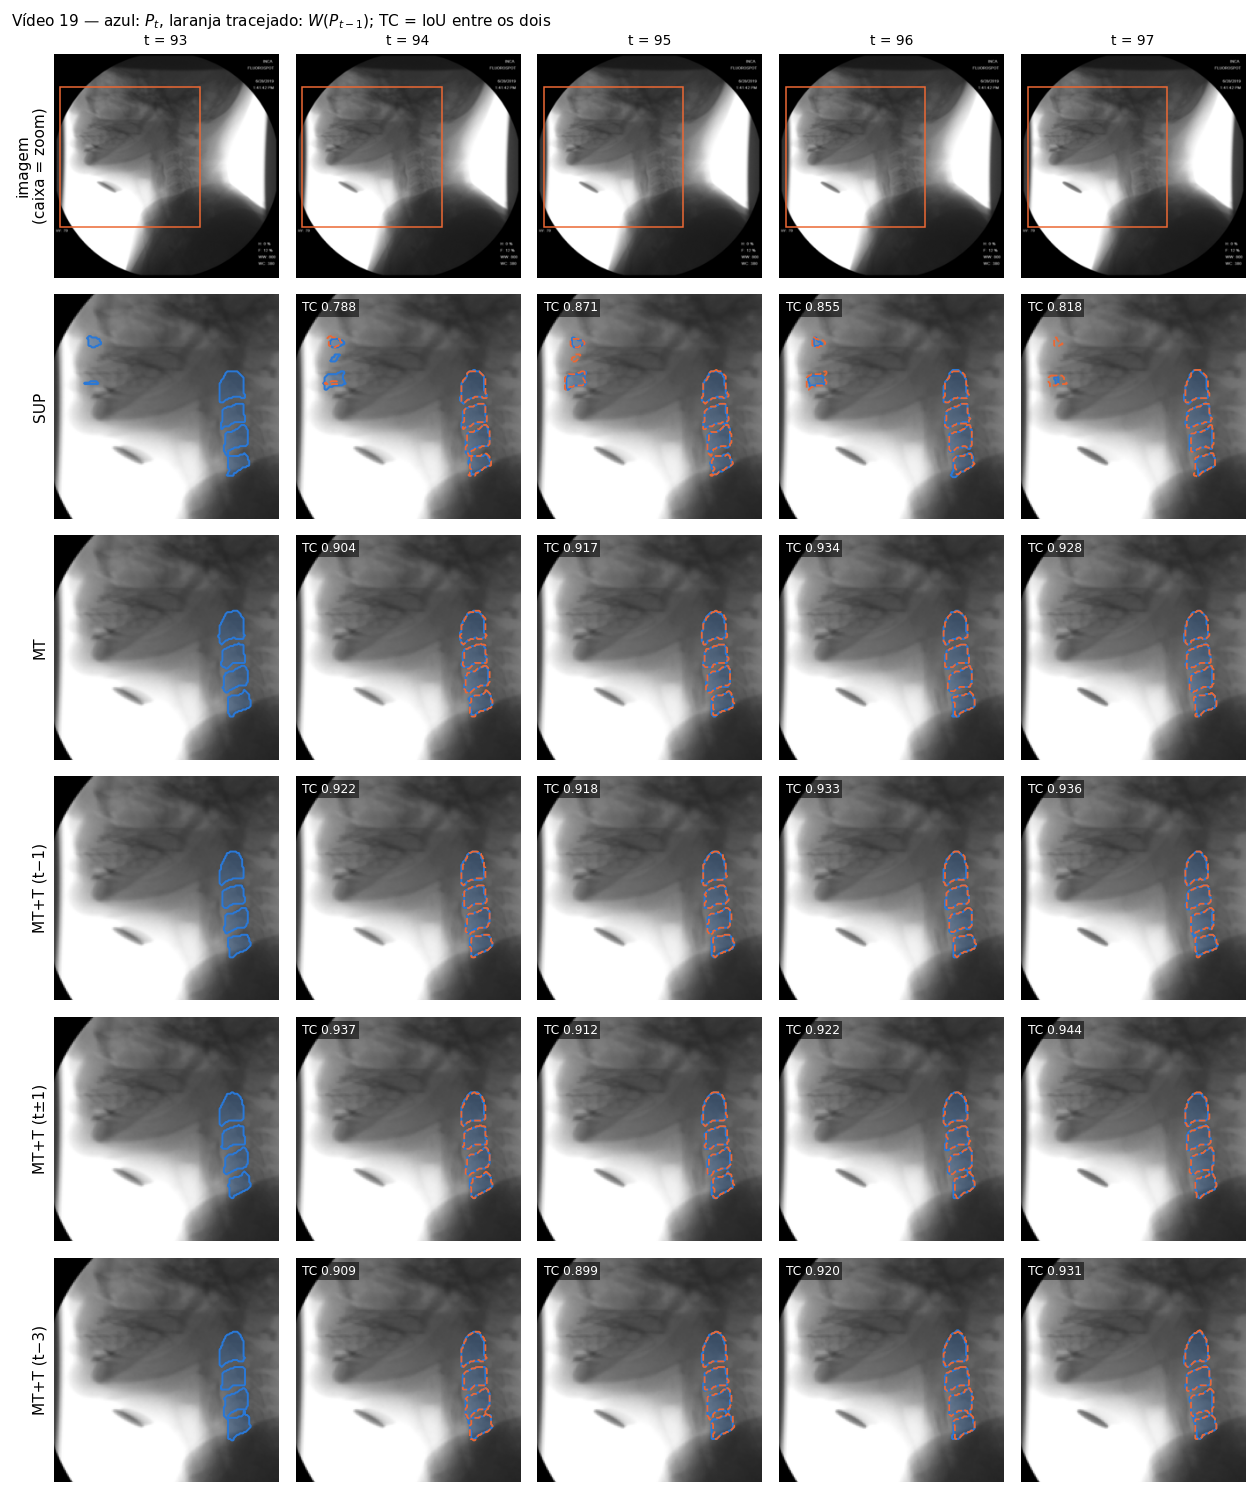

In [10]:
ZOOM_MARGIN = 20           # px em volta da união das máscaras; None mostra o quadro inteiro


def zoom_box(video_id, frames, methods, margin):
    """Caixa quadrada (x0, x1, y0, y1) em volta da união das máscaras de todos os métodos na janela."""
    union = np.zeros((SIZE, SIZE), bool)
    for method in methods:
        for f in frames:
            union |= masks_of(method, video_id)[f]
    if margin is None or not union.any():
        return 0, SIZE, 0, SIZE
    ys, xs = np.nonzero(union)
    side = int(max(np.ptp(xs), np.ptp(ys))) + 2 * margin
    cx, cy = (xs.min() + xs.max()) / 2, (ys.min() + ys.max()) / 2
    x0 = int(np.clip(cx - side / 2, 0, max(SIZE - side, 0)))
    y0 = int(np.clip(cy - side / 2, 0, max(SIZE - side, 0)))
    return x0, min(x0 + side, SIZE), y0, min(y0 + side, SIZE)


def plot_window(video_id, start, methods=MAIN, n=WINDOW_LEN, margin=ZOOM_MARGIN):
    frames = list(range(start, start + n))
    images = [photo(video_id, f) for f in frames]
    flows = [flow_fw(video_id, f) for f in frames[:-1]]
    x0, x1, y0, y1 = zoom_box(video_id, frames, methods, margin)
    fig, axes = plt.subplots(len(methods) + 1, n, figsize=(2.3 * n, 2.3 * (len(methods) + 1)))
    for j, f in enumerate(frames):
        axes[0, j].imshow(images[j], cmap="gray", vmin=0, vmax=1)
        axes[0, j].add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec=C2, lw=1))
        axes[0, j].set_title(f"t = {f}", fontsize=9)
    axes[0, 0].set_ylabel("imagem\n(caixa = zoom)", fontsize=10)
    for i, method in enumerate(methods, start=1):
        masks = masks_of(method, video_id)
        tc = inca[(inca.method == method) & (inca.video_id == video_id)].set_index("frame_t").tc_iou
        for j, f in enumerate(frames):
            ax = axes[i, j]
            ax.imshow(images[j], cmap="gray", vmin=0, vmax=1)
            P = masks[f]
            ax.imshow(np.ma.masked_where(~P, P), cmap=plt.matplotlib.colors.ListedColormap([C1]), alpha=0.25)
            ax.contour(P.astype(float), levels=[0.5], colors=[C1], linewidths=1.3)
            if j > 0:
                moved = transport_masks(torch.from_numpy(masks[f - 1])[None, None], flows[j - 1],
                                        settings["warp_convention"])[0, 0].numpy()
                ax.contour(moved.astype(float), levels=[0.5], colors=[C2], linewidths=1.2, linestyles="--")
                ax.text(0.03, 0.97, f"TC {tc.get(f - 1, np.nan):.3f}", color="white", fontsize=8, va="top",
                        transform=ax.transAxes, bbox=dict(facecolor="black", alpha=0.55, pad=1.5, lw=0))
            ax.set_xlim(x0, x1)
            ax.set_ylim(y1, y0)
        axes[i, 0].set_ylabel(LABELS[method], fontsize=10)
    for ax in axes.flat:
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        for s in ax.spines.values():
            s.set_visible(False)
    fig.suptitle(f"Vídeo {video_id} — azul: $P_t$, laranja tracejado: $W(P_{{t-1}})$; "
                 f"TC = IoU entre os dois", fontsize=10, x=0.01, ha="left")
    fig.tight_layout()
    return fig


fig = plot_window(video_sel, start_sel)
fig.savefig(FIG_DIR / f"qualitativo_v{video_sel}_f{start_sel}.png", dpi=200, bbox_inches="tight")

### Vídeo completo com as predições sobrepostas

Um painel por método. A faixa de baixo é a TC-IoU do par $(t-1, t)$ ao longo do vídeo (eixo de 0,5 a 1), e
o cursor branco marca o frame atual. O vídeo é gravado como `.webm` (VP9, embutido abaixo; toca no
navegador e no VS Code) e `.mp4` (mp4v, para slides). `VIDEO_ID` padrão: o vídeo da janela acima.

In [11]:
VIDEO_ID = video_sel
FPS = 12
STRIP_H, HEADER_H = 56, 22
BGR = {"fill": (214, 120, 42), "edge": (214, 120, 42), "text": (255, 255, 255), "trace": (52, 104, 235)}


def ascii_label(method):
    return LABELS[method].replace("−", "-").replace("±", "+-")


def render_video(video_id, methods=MAIN, fps=FPS, tc_floor=0.5):
    masks = {m: masks_of(m, video_id) for m in methods}
    frames = sorted(masks[methods[0]])
    tcs = {m: inca[(inca.method == m) & (inca.video_id == video_id)].set_index("frame_t").tc_iou for m in methods}
    W, H = SIZE * len(methods), HEADER_H + SIZE + STRIP_H
    paths = {"webm": FIG_DIR / f"video_v{video_id}.webm", "mp4": FIG_DIR / f"video_v{video_id}.mp4"}
    writers = [cv2.VideoWriter(str(paths["webm"]), cv2.VideoWriter_fourcc(*"VP90"), fps, (W, H)),
               cv2.VideoWriter(str(paths["mp4"]), cv2.VideoWriter_fourcc(*"mp4v"), fps, (W, H))]

    def y_of(v):
        return int(HEADER_H + SIZE + STRIP_H - 4 - (np.clip(v, tc_floor, 1) - tc_floor) / (1 - tc_floor) * (STRIP_H - 8))

    for k, f in enumerate(frames):
        gray = (photo(video_id, f) * 255).astype(np.uint8)
        canvas = np.zeros((H, W, 3), np.uint8)
        for i, m in enumerate(methods):
            x0 = i * SIZE
            panel = cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)
            P = masks[m][f].astype(np.uint8)
            fill = panel.copy(); fill[P > 0] = BGR["fill"]
            panel = cv2.addWeighted(fill, 0.3, panel, 0.7, 0)
            contours, _ = cv2.findContours(P, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
            cv2.drawContours(panel, contours, -1, BGR["edge"], 1)
            canvas[HEADER_H:HEADER_H + SIZE, x0:x0 + SIZE] = panel
            cv2.putText(canvas, ascii_label(m), (x0 + 6, 16), cv2.FONT_HERSHEY_SIMPLEX, 0.5, BGR["text"], 1, cv2.LINE_AA)
            series = tcs[m].reindex(frames[:-1])
            pts = np.array([[x0 + int(j / max(len(frames) - 1, 1) * (SIZE - 1)), y_of(v)]
                            for j, v in enumerate(series.values) if np.isfinite(v)], np.int32)
            cv2.line(canvas, (x0, y_of(1.0)), (x0 + SIZE - 1, y_of(1.0)), (70, 70, 70), 1)
            if len(pts) > 1:
                cv2.polylines(canvas, [pts], False, BGR["trace"], 1, cv2.LINE_AA)
            cx = x0 + int(k / max(len(frames) - 1, 1) * (SIZE - 1))
            cv2.line(canvas, (cx, HEADER_H + SIZE + 2), (cx, H - 2), (255, 255, 255), 1)
            value = series.get(f - 1, np.nan)
            if np.isfinite(value):
                cv2.putText(canvas, f"TC {value:.3f}", (x0 + SIZE - 78, 16), cv2.FONT_HERSHEY_SIMPLEX, 0.42,
                            BGR["text"], 1, cv2.LINE_AA)
            cv2.line(canvas, (x0, 0), (x0, H), (40, 40, 40), 1)
        cv2.putText(canvas, f"frame {f}", (W - 90, H - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (180, 180, 180), 1, cv2.LINE_AA)
        for writer in writers:
            writer.write(canvas)
    for writer in writers:
        writer.release()
    return paths


video_paths = render_video(VIDEO_ID)
print({k: str(v.relative_to(ROOT)) for k, v in video_paths.items()})
Video(str(video_paths["webm"]), embed=True, mimetype="video/webm", width=min(1100, SIZE * len(MAIN)))

OpenCV: FFMPEG: tag 0x30395056/'VP90' is not supported with codec id 167 and format 'webm / WebM'


{'webm': 'logs/_arquivo/e2-sem-aug/temporal/figuras/video_v19.webm', 'mp4': 'logs/_arquivo/e2-sem-aug/temporal/figuras/video_v19.mp4'}


## 5. Validação do fluxo

A TC só mede estabilidade se o fluxo explicar o movimento real. São três checagens:

1. **Alinhamento visual** em pares com movimento típico (mediana) e grande (p95) dentro da ROI. Se o warp
   explicou o movimento, $|I_{t+1}-W(I_t)|$ fica mais escuro que $|I_{t+1}-I_t|$.
2. **Erro de reconstrução** fotométrico L1, warp contra identidade, na ROI: a união das predições de todos
   os métodos, dilatada 15 px, ou seja, a região das estruturas, sem usar GT.
3. **Transporte da GT** nos pares consecutivos **anotados**: Dice$(W(G_t), G_{t+1})$ contra
   Dice$(G_t, G_{t+1})$. Atenção: GTs consecutivas têm ruído de anotação (Dice ≈ 0,88 entre si na avaliação
   de flow anterior). Esse ruído põe um teto baixo no ganho possível.

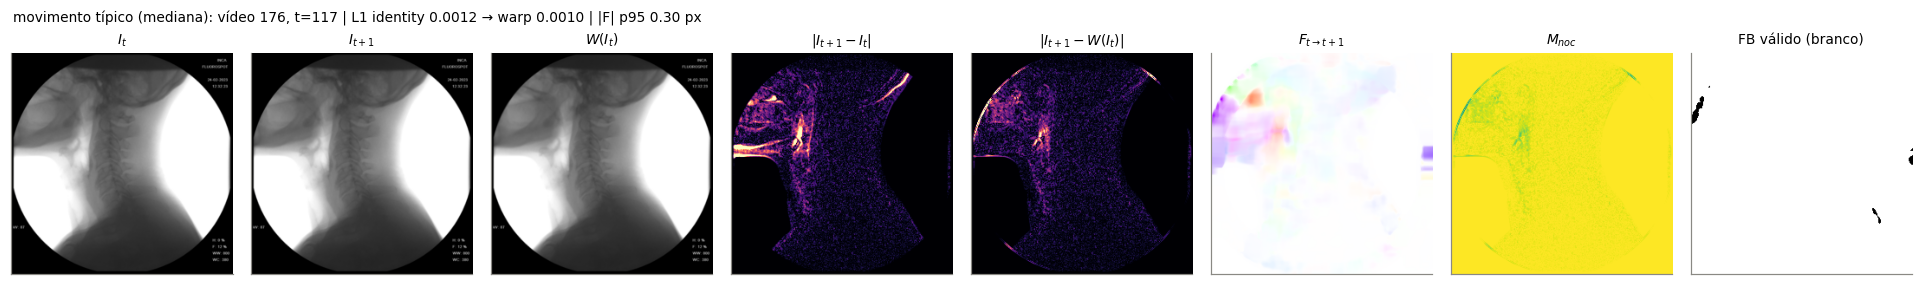

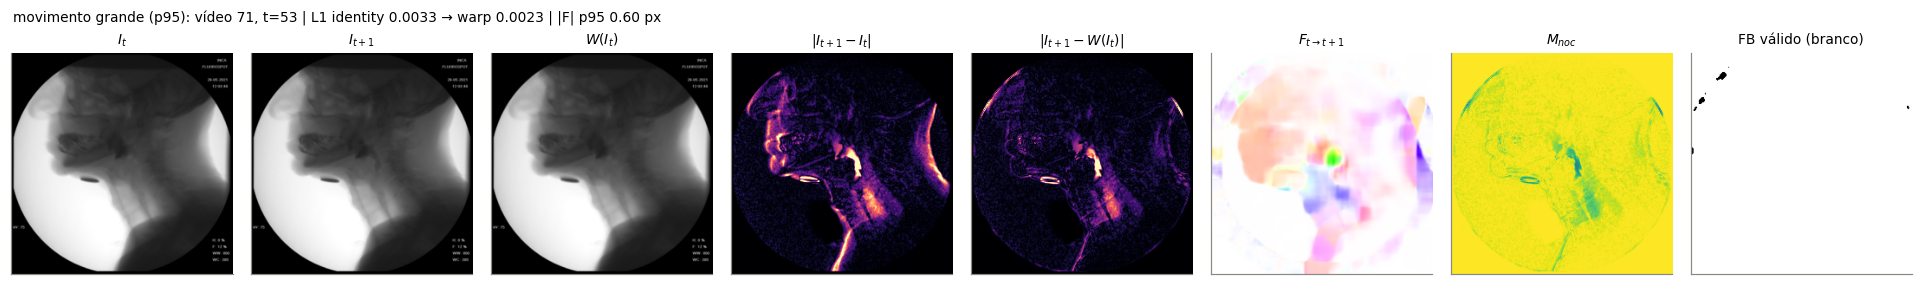

In [12]:
def alignment_example(video_id, t, title):
    I_t, I_t1 = photo(video_id, t), photo(video_id, t + 1)
    kw = settings["flow_kwargs"]
    args = dict(method=kw["method"], preprocess=kw["preprocess"], farneback_params=kw["farneback_params"],
                median_ksize=kw["median_ksize"])
    fw = torch.from_numpy(compute_flow(I_t, I_t1, **args))[None]
    bw = torch.from_numpy(compute_flow(I_t1, I_t, **args))[None]
    conf = pair_confidence(torch.from_numpy(I_t)[None, None], torch.from_numpy(I_t1)[None, None], fw, bw,
                           settings["noc_alpha"], settings["warp_convention"])
    I_w = conf["I_warp"][0, 0].numpy()
    d_id, d_w = np.abs(I_t1 - I_t), np.abs(I_t1 - I_w)
    vmax = np.percentile(d_id, 99.5) + 1e-6
    panels = [(I_t, r"$I_t$", "gray", (0, 1)), (I_t1, r"$I_{t+1}$", "gray", (0, 1)),
              (I_w, r"$W(I_t)$", "gray", (0, 1)),
              (d_id, r"$|I_{t+1} - I_t|$", "magma", (0, vmax)), (d_w, r"$|I_{t+1} - W(I_t)|$", "magma", (0, vmax)),
              (flow_to_image(fw)[0].permute(1, 2, 0).numpy(), r"$F_{t\to t+1}$", None, None),
              (conf["mnoc"][0, 0].numpy(), r"$M_{noc}$", "viridis", (0, 1)),
              (conf["fb_valid"][0, 0].numpy(), "FB válido (branco)", "gray", (0, 1))]
    fig, axes = plt.subplots(1, len(panels), figsize=(2.2 * len(panels), 2.6))
    for ax, (img, name, cmap, lim) in zip(axes, panels):
        ax.imshow(img, cmap=cmap, vmin=None if lim is None else lim[0], vmax=None if lim is None else lim[1])
        ax.set_title(name, fontsize=9)
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    mag = np.linalg.norm(fw[0].numpy(), axis=0)
    fig.suptitle(f"{title}: vídeo {video_id}, t={t} | L1 identity {d_id.mean():.4f} → warp {d_w.mean():.4f} "
                 f"| |F| p95 {np.percentile(mag, 95):.2f} px", fontsize=9, x=0.01, ha="left")
    fig.tight_layout()
    return fig


inca_flow = flowq[flowq.eval_set == "inca_test"].dropna(subset=["flow_mag_p95_roi"])
for q, title in ((0.5, "movimento típico (mediana)"), (0.95, "movimento grande (p95)")):
    target = inca_flow.flow_mag_p95_roi.quantile(q)
    ex = inca_flow.loc[(inca_flow.flow_mag_p95_roi - target).abs().idxmin()]
    fig = alignment_example(int(ex.video_id), int(ex.frame_t), title)
    fig.savefig(FIG_DIR / f"fluxo_alinhamento_q{int(q * 100)}.png", dpi=200, bbox_inches="tight")

In [13]:
flow_patient = aggregate_video_patient(
    flowq.assign(gain_roi=flowq.l1_identity_roi - flowq.l1_warp_roi,
                 warp_better=(flowq.l1_warp_roi < flowq.l1_identity_roi).astype(float)),
    ["l1_identity_roi", "l1_warp_roi", "gain_roi", "warp_better", "l1_identity_full", "l1_warp_full",
     "flow_mag_p95_roi", "mnoc_roi", "fb_valid_roi"], by=["eval_set"])

# Quanto o transporte muda a própria TC: se o movimento entre frames consecutivos for sub-pixel, o warp
# quase não altera a máscara, e a TC se reduz à sobreposição crua de P_t e P_{t+1}.
warp_effect = (pairs.assign(d=(pairs.tc_iou - pairs.tc_iou_identity).abs(),
                            changed=(pairs.tc_iou != pairs.tc_iou_identity))
               .groupby("eval_set").agg(d=("d", "mean"), changed=("changed", "mean")))
rows = []
for eval_set, g in flow_patient.groupby("eval_set"):
    stat = wilcoxon(g.l1_warp_roi, g.l1_identity_roi)
    pair_mag = flowq[flowq.eval_set == eval_set].flow_mag_p95_roi
    rows.append({"conjunto": EVAL_SETS[eval_set], "pacientes": len(g),
                 "|F| p95 ROI, mediana dos pares (px)": pair_mag.median(),
                 "|F| p95 ROI, p90 dos pares (px)": pair_mag.quantile(0.9),
                 "pares em que o warp muda a TC (%)": 100 * warp_effect.loc[eval_set, "changed"],
                 "|TC warp − TC identity| médio": warp_effect.loc[eval_set, "d"],
                 "L1 ROI identity": g.l1_identity_roi.mean(), "L1 ROI warp": g.l1_warp_roi.mean(),
                 "redução relativa (%)": 100 * (1 - g.l1_warp_roi.mean() / g.l1_identity_roi.mean()),
                 "pares com warp < identity (%)": 100 * g.warp_better.mean(),
                 "pacientes com warp < identity": f"{(g.l1_warp_roi < g.l1_identity_roi).sum()}/{len(g)}",
                 "p Wilcoxon": stat.pvalue,
                 "|F| p95 na ROI (px)": g.flow_mag_p95_roi.mean(),
                 "M_noc ROI": g.mnoc_roi.mean(), "FB válido ROI (%)": 100 * g.fb_valid_roi.mean()})
flow_table = pd.DataFrame(rows)
flow_table.to_csv(TC_DIR / "tabela_fluxo.csv", index=False)
flow_table.round(4)

,conjunto,pacientes,"|F| p95 ROI, mediana dos pares (px)","|F| p95 ROI, p90 dos pares (px)",pares em que o warp muda a TC (%),|TC warp − TC identity| médio,L1 ROI identity,L1 ROI warp,redução relativa (%),pares com warp < identity (%),pacientes com warp < identity,p Wilcoxon,|F| p95 na ROI (px),M_noc ROI,FB válido ROI (%)
0,Teste INCA,23,0.1756,0.6166,9.3556,0.0005,0.0028,0.0026,8.3852,90.5877,23/23,0.0,0.3281,0.9678,99.973701
1,UNM,35,0.3318,1.2820,26.5329,0.0031,0.0036,0.0030,15.5829,87.5314,35/35,0.0,0.6534,0.9636,99.722900


O erro de reconstrução **em função do movimento**: os pares são agrupados por $|F|$ p95 na ROI. Onde quase
nada se move, warp e identidade empatam. O fluxo precisa ganhar justamente onde há movimento, que é onde
a TC sem transporte puniria um método estável.

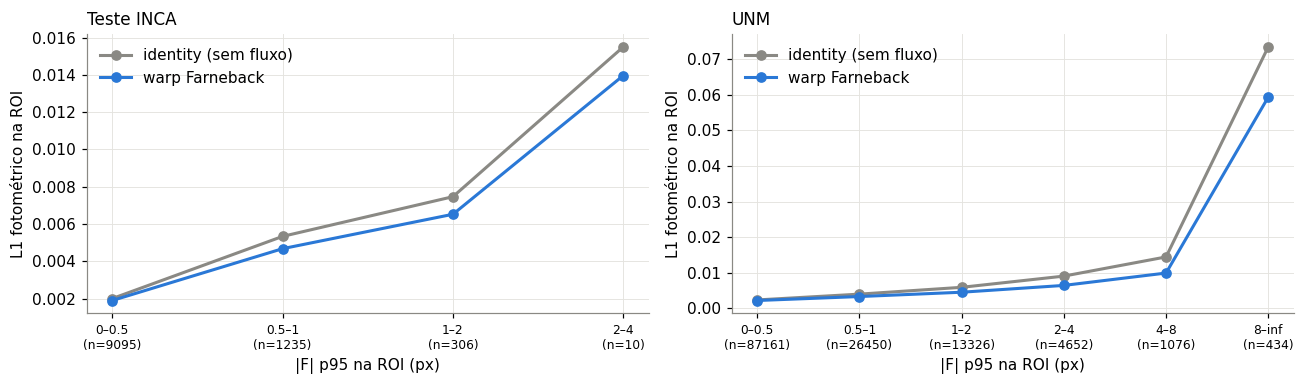

In [14]:
MOTION_BINS = [0, 0.5, 1, 2, 4, 8, np.inf]
sets = [s for s in EVAL_SETS if s in flowq.eval_set.unique()]
fig, axes = plt.subplots(1, len(sets), figsize=(6 * len(sets), 3.6), squeeze=False)
for ax, eval_set in zip(axes[0], sets):
    g = flowq[flowq.eval_set == eval_set].dropna(subset=["flow_mag_p95_roi", "l1_warp_roi"])
    g = g.assign(bin=pd.cut(g.flow_mag_p95_roi, MOTION_BINS, right=False))
    agg = g.groupby("bin", observed=True).agg(identity=("l1_identity_roi", "mean"), warp=("l1_warp_roi", "mean"),
                                              n=("l1_warp_roi", "size"))
    xs = np.arange(len(agg))
    ax.plot(xs, agg.identity, "-o", color=MUTED, lw=2, ms=6, label="identity (sem fluxo)")
    ax.plot(xs, agg.warp, "-o", color=C1, lw=2, ms=6, label="warp Farneback")
    ax.set_xticks(xs, [f"{iv.left:g}–{iv.right:g}\n(n={n})" for iv, n in zip(agg.index, agg.n)], fontsize=8)
    ax.set_xlabel("|F| p95 na ROI (px)")
    ax.set_ylabel("L1 fotométrico na ROI")
    ax.set_title(EVAL_SETS[eval_set], loc="left")
    ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "fluxo_erro_reconstrucao_por_movimento.png", dpi=200, bbox_inches="tight")

In [15]:
if len(gt_pairs):
    rows = []
    for eval_set, g in gt_pairs.groupby("eval_set"):
        d = g.gt_dice_warp - g.gt_dice_identity
        rows.append({"conjunto": EVAL_SETS[eval_set], "pares anotados consecutivos": len(g),
                     "pacientes": g.paciente_id.nunique(),
                     "Dice(G_t, G_t+1) sem warp": g.gt_dice_identity.mean(),
                     "Dice(W(G_t), G_t+1)": g.gt_dice_warp.mean(), "Δ médio": d.mean(),
                     "pares em que o warp ajuda (%)": 100 * (d > 0).mean(),
                     "pares em que piora (%)": 100 * (d < 0).mean(),
                     "p Wilcoxon (pares)": wilcoxon(d).pvalue if (d != 0).any() else np.nan})
    gt_table = pd.DataFrame(rows)
    gt_table.to_csv(TC_DIR / "tabela_fluxo_gt.csv", index=False)
    display(gt_table.round(4))
else:
    print("Nenhum par consecutivo anotado nos vídeos avaliados.")

,conjunto,pares anotados consecutivos,pacientes,"Dice(G_t, G_t+1) sem warp","Dice(W(G_t), G_t+1)",Δ médio,pares em que o warp ajuda (%),pares em que piora (%),p Wilcoxon (pares)
0,Teste INCA,47,11,0.8934,0.8934,-0.0000,2.1277,4.2553,0.285
1,UNM,7,6,0.9194,0.9151,-0.0042,0.0000,14.2857,1.000


## 6. O peso de confiança da estimativa de movimento ($M_{noc}$ e FB)

No treino, a perda temporal pondera cada pixel por $M_{noc}$ (`temporal_use_confidence: True`). A hipótese
implícita é que **$M_{noc}$ baixo marca onde o transporte erra**. Aqui isso é testado, junto com a
alternativa clássica: o teste forward-backward (FB).

- **AUROC** de $1-\text{confiança}$ para prever o pixel errado do transporte, na faixa de ±5 px em torno das
  bordas, onde o erro de transporte acontece. Há duas camadas de "erro":
  - **GT**: $W(G_t)\ne G_{t+1}$ nos pares anotados. Inclui o ruído de anotação.
  - **Predição**: $W(P_t)\ne P_{t+1}$, o desacordo que a perda temporal de fato pondera. Mistura erro de
    fluxo e instabilidade do modelo.
- AUROC 0,5 = a confiança não separa erro de acerto. Ela é calculada por paciente (histogramas por vídeo
  somados no paciente) e depois resumida em média ± dp. A linha `agregado` soma tudo.
- **Curva de confiabilidade:** taxa de erro por faixa de confiança. Um peso útil tem erro alto à esquerda
  e baixo à direita.

In [16]:
LAYER = {RUN_OF[m]: m for m in RUN_OF} | {"gt": "gt"}
counts = conf_counts.assign(layer=conf_counts.layer.map(LAYER))
BINS = settings["confidence_bins"]


def hist(g):
    h = np.zeros((BINS, 2), np.int64)
    np.add.at(h, (g.bin.values, 0), g.n_ok.values)
    np.add.at(h, (g.bin.values, 1), g.n_err.values)
    return h


rows = []
for (eval_set, layer, confidence), g in counts.groupby(["eval_set", "layer", "confidence"]):
    per_patient_auc = [auroc_from_counts(hist(p)) for _, p in g.groupby("paciente_id")]
    per_patient_auc = np.array([a for a in per_patient_auc if np.isfinite(a)])
    h = hist(g)
    rows.append({"eval_set": eval_set, "camada": "GT" if layer == "gt" else LABELS.get(layer, layer),
                 "confiança": "M_noc" if confidence == "mnoc" else "FB", "AUROC agregado": auroc_from_counts(h),
                 "AUROC por paciente (média)": per_patient_auc.mean() if len(per_patient_auc) else np.nan,
                 "dp": per_patient_auc.std(ddof=1) if len(per_patient_auc) > 1 else np.nan,
                 "pacientes": len(per_patient_auc), "pixels na faixa": int(h.sum()),
                 "taxa de erro na faixa": h[:, 1].sum() / max(h.sum(), 1),
                 "frac. pixels com confiança < 0,9": h[: int(0.9 * BINS)].sum() / max(h.sum(), 1),
                 "taxa de erro, confiança < 0,9": h[: int(0.9 * BINS), 1].sum() / max(h[: int(0.9 * BINS)].sum(), 1),
                 "taxa de erro, confiança ≥ 0,9": h[int(0.9 * BINS):, 1].sum() / max(h[int(0.9 * BINS):].sum(), 1)})
auroc_table = pd.DataFrame(rows)
order = {"GT": -1, **{LABELS[m]: i for i, m in enumerate(METHODS)}}
auroc_table = auroc_table.sort_values(["eval_set", "confiança", "camada"], key=lambda s: s.map(order) if s.name == "camada" else s)
auroc_table.to_csv(TC_DIR / "tabela_confianca_auroc.csv", index=False)
auroc_table.round(3)

,eval_set,camada,confiança,AUROC agregado,AUROC por paciente (média),dp,pacientes,pixels na faixa,taxa de erro na faixa,"frac. pixels com confiança < 0,9","taxa de erro, confiança < 0,9","taxa de erro, confiança ≥ 0,9"
2,inca_test,GT,FB,0.500,0.500,0.000,11,161401,0.089,0.000,0.000,0.089
12,inca_test,SUP,FB,0.500,0.500,0.000,23,35957038,0.028,0.000,0.027,0.028
4,inca_test,MT,FB,0.500,0.500,0.000,23,35096339,0.023,0.000,0.034,0.023
8,inca_test,MT+T (t−1),FB,0.500,0.500,0.000,23,34164612,0.022,0.000,0.033,0.022
6,inca_test,MT+T (t±1),FB,0.500,0.500,0.000,23,34991031,0.022,0.000,0.033,0.022
10,inca_test,MT+T (t−3),FB,0.500,0.500,0.000,23,34666551,0.023,0.000,0.036,0.023
0,inca_test,FixMatch,FB,0.500,0.500,0.000,23,35712131,0.025,0.000,0.023,0.025
3,inca_test,GT,M_noc,0.493,0.489,0.021,11,161401,0.089,0.007,0.066,0.089
13,inca_test,SUP,M_noc,0.537,0.532,0.030,23,35957038,0.028,0.032,0.057,0.027
5,inca_test,MT,M_noc,0.542,0.536,0.029,23,35096339,0.023,0.031,0.051,0.022


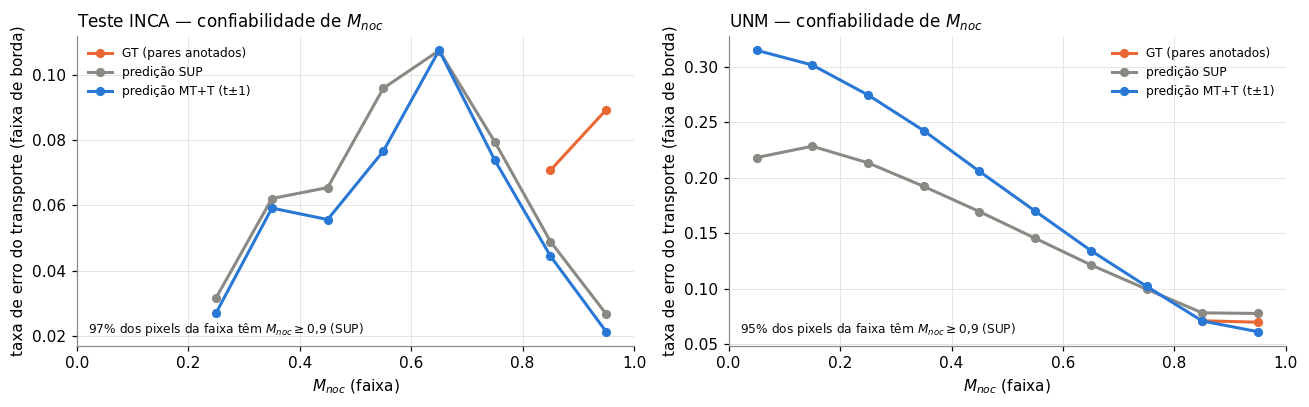

In [17]:
fig, axes = plt.subplots(1, len(sets), figsize=(6 * len(sets), 3.8), squeeze=False)
for ax, eval_set in zip(axes[0], sets):
    for layer, color, name in (("gt", C2, "GT (pares anotados)"), ("supervised", MUTED, "predição SUP"),
                               (FOCUS, C1, f"predição {LABELS[FOCUS]}")):
        g = counts[(counts.eval_set == eval_set) & (counts.layer == layer) & (counts.confidence == "mnoc")]
        if g.empty:
            continue
        rel = reliability_from_counts(hist(g), n_groups=10)
        rel = rel[rel.n >= 200]
        ax.plot((rel.conf_lo + rel.conf_hi) / 2, rel.error_rate, "-o", color=color, lw=2, ms=5, label=name)
    sup = counts[(counts.eval_set == eval_set) & (counts.layer == "supervised") & (counts.confidence == "mnoc")]
    if len(sup):
        h = hist(sup)
        ax.text(0.02, 0.04, f"{100 * h[int(0.9 * BINS):].sum() / h.sum():.0f}% dos pixels da faixa têm "
                f"$M_{{noc}}\\geq 0{{,}}9$ (SUP)", transform=ax.transAxes, fontsize=8, color=INK)
    ax.set_xlabel(r"$M_{noc}$ (faixa)")
    ax.set_ylabel("taxa de erro do transporte (faixa de borda)")
    ax.set_xlim(0, 1)
    ax.set_title(f"{EVAL_SETS[eval_set]} — confiabilidade de $M_{{noc}}$", loc="left")
    ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "confianca_mnoc_confiabilidade.png", dpi=200, bbox_inches="tight")

**A ponderação muda a conclusão?** Se o ranking dos métodos (e a diferença pareada contra o SUP) é o
mesmo com TC crua, ponderada por $M_{noc}$ e restrita a FB, então a conclusão não depende do peso de
confiança. Também mostramos quanto da imagem o peso de fato rebaixa.

In [18]:
rank_rows = []
for eval_set, g in per_patient[per_patient.method.isin(MAIN)].groupby("eval_set"):
    means = g.groupby("method")[["tc_iou", "tc_iou_mnoc", "tc_iou_fb"]].mean()
    for variant in ("tc_iou_mnoc", "tc_iou_fb"):
        tau = kendalltau(means.tc_iou, means[variant]).statistic
        rank_rows.append({"conjunto": EVAL_SETS[eval_set], "variante": variant,
                          "Kendall τ (ranking vs TC crua)": tau,
                          "ranking crua": " > ".join(LABELS[m] for m in means.tc_iou.sort_values(ascending=False).index),
                          "ranking variante": " > ".join(LABELS[m] for m in means[variant].sort_values(ascending=False).index)})
display(pd.DataFrame(rank_rows))
display(diffs[diffs.metric.isin(["tc_iou", "tc_iou_mnoc", "tc_iou_fb"]) & (diffs.b == "supervised")]
        .pivot_table(index=["eval_set", "comparação"], columns="metric", values="mean_diff", sort=False).round(4))

,conjunto,variante,Kendall τ (ranking vs TC crua),ranking crua,ranking variante
0,Teste INCA,tc_iou_mnoc,1.0,MT+T (t±1) > MT+T (t−1) > MT > MT+T (t−3) > SUP,MT+T (t±1) > MT+T (t−1) > MT > MT+T (t−3) > SUP
1,Teste INCA,tc_iou_fb,1.0,MT+T (t±1) > MT+T (t−1) > MT > MT+T (t−3) > SUP,MT+T (t±1) > MT+T (t−1) > MT > MT+T (t−3) > SUP
2,UNM,tc_iou_mnoc,1.0,MT+T (t−1) > MT+T (t±1) > MT > MT+T (t−3) > SUP,MT+T (t−1) > MT+T (t±1) > MT > MT+T (t−3) > SUP
3,UNM,tc_iou_fb,1.0,MT+T (t−1) > MT+T (t±1) > MT > MT+T (t−3) > SUP,MT+T (t−1) > MT+T (t±1) > MT > MT+T (t−3) > SUP


metric                      tc_iou  tc_iou_mnoc  tc_iou_fb
eval_set  comparação                                      
inca_test MT − SUP          0.0119       0.0119     0.0119
          MT+T (t−1) − SUP  0.0124       0.0124     0.0124
          MT+T (t±1) − SUP  0.0130       0.0130     0.0130
          MT+T (t−3) − SUP  0.0092       0.0092     0.0092
unm       MT − SUP          0.0447       0.0448     0.0446
          MT+T (t−1) − SUP  0.0656       0.0661     0.0656
          MT+T (t±1) − SUP  0.0628       0.0631     0.0627
          MT+T (t−3) − SUP  0.0260       0.0262     0.0260

## 7. Texto para o artigo (gerado dos números acima)

Rascunho com os valores preenchidos automaticamente. Com os runs sem augmentation, os números **não** são
os finais. Rerodar o notebook depois de `scripts/e2_temporal.py` no `logs/e2`.

In [19]:
def m(eval_set, method, metric):
    r = summary[(summary.eval_set == eval_set) & (summary.method == method)]
    return r[f"{metric}_mean"].item() if len(r) else np.nan

def dd(eval_set, a, b, metric):
    r = diffs[(diffs.eval_set == eval_set) & (diffs.a == a) & (diffs.b == b) & (diffs.metric == metric)]
    return r.iloc[0] if len(r) else None

def say(r, digits=3):
    return "n/d" if r is None else (f"{r.mean_diff:+.{digits}f} (IC95% {r.ci_lo:+.{digits}f} a {r.ci_hi:+.{digits}f}; "
                                    + ("p Holm < 0,001)" if r.p_holm < 0.001 else f"p Holm = {r.p_holm:.3f})"))

text = []
text.append(
    "**Métodos.** A estabilidade temporal foi medida pela consistência temporal TC-IoU_t = "
    "IoU(W(P_t, F_{t→t+1}), P_{t+1}) (e TC-Dice, análogo) em todos os pares de frames consecutivos dos vídeos de "
    "teste, rotulados ou não. P é a máscara prevista pelo caminho de avaliação de cada método; F é o fluxo óptico de "
    f"Farneback ({settings['flow_kwargs']['preprocess']}, parâmetros do DTC-TRUS), o mesmo usado na perda temporal; "
    "W é o warp bilinear com limiar 0,5. A TC foi promediada por vídeo, depois por paciente, e as comparações "
    "entre métodos foram pareadas por paciente (bootstrap de pacientes para o IC95%; Wilcoxon com correção de Holm). "
    "O fluxo foi validado pelo erro de reconstrução fotométrico e pelo transporte das anotações em pares consecutivos "
    "anotados. O peso de confiança M_noc = exp(−α|I_{t+1} − W(I_t)|) e o teste forward-backward foram avaliados "
    "pela AUROC para detectar pixels de transporte incorreto na faixa de borda.")
for eval_set in sets:
    sup, mt, foc = (m(eval_set, x, "tc_iou") for x in ("supervised", "meanteacher", FOCUS))
    text.append(
        f"**Resultados — {EVAL_SETS[eval_set]}.** TC-IoU (média por paciente): SUP {sup:.3f}, MT {mt:.3f}, "
        f"{LABELS[FOCUS]} {foc:.3f}. Diferença pareada {LABELS[FOCUS]} − SUP: {say(dd(eval_set, FOCUS, 'supervised', 'tc_iou'))}; "
        f"MT − SUP: {say(dd(eval_set, 'meanteacher', 'supervised', 'tc_iou'))}; "
        f"{LABELS[FOCUS]} − MT: {say(dd(eval_set, FOCUS, 'meanteacher', 'tc_iou'))}. "
        f"No Dice, {LABELS[FOCUS]} − SUP = {say(dd(eval_set, FOCUS, 'supervised', 'dice'))}.")
for _, r in flow_table.iterrows():
    text.append(
        f"**Fluxo — {r['conjunto']}.** O warp reduziu o erro fotométrico L1 na ROI de {r['L1 ROI identity']:.4f} "
        f"para {r['L1 ROI warp']:.4f} ({r['redução relativa (%)']:.1f}%; menor que a identidade em "
        f"{r['pares com warp < identity (%)']:.0f}% dos pares; p = {r['p Wilcoxon']:.2g}). O movimento entre frames "
        f"consecutivos é sub-pixel na resolução de entrada (mediana do p95 de |F| na ROI = "
        f"{r['|F| p95 ROI, mediana dos pares (px)']:.2f} px; p90 = {r['|F| p95 ROI, p90 dos pares (px)']:.2f} px): o "
        f"transporte altera a TC em {r['pares em que o warp muda a TC (%)']:.0f}% dos pares, em média "
        f"{r['|TC warp − TC identity| médio']:.4f}. Em t→t+1, portanto, a TC mede sobretudo a oscilação da "
        "predição entre frames quase idênticos, e não a capacidade de acompanhar movimento.")
if len(gt_pairs):
    for _, r in gt_table.iterrows():
        text.append(
            f"Nos {r['pares anotados consecutivos']} pares consecutivos anotados ({r['conjunto']}), o Dice da GT "
            f"transportada foi {r['Dice(W(G_t), G_t+1)']:.3f} contra {r['Dice(G_t, G_t+1) sem warp']:.3f} sem transporte.")
for eval_set in sets:
    a = auroc_table[(auroc_table.eval_set == eval_set) & (auroc_table.camada == "GT")].set_index("confiança")
    b = auroc_table[(auroc_table.eval_set == eval_set) & (auroc_table.camada == "SUP")].set_index("confiança")
    if len(b):
        text.append(
            f"**Confiança — {EVAL_SETS[eval_set]}.** AUROC de 1−M_noc para o erro de transporte: "
            + (f"{a.loc['M_noc', 'AUROC agregado']:.3f} (GT), " if "M_noc" in a.index else "")
            + f"{b.loc['M_noc', 'AUROC agregado']:.3f} (predições SUP); teste FB: "
            + (f"{a.loc['FB', 'AUROC agregado']:.3f} (GT), " if "FB" in a.index else "")
            + f"{b.loc['FB', 'AUROC agregado']:.3f} (predições SUP). "
            + f"{100 * (1 - b.loc['M_noc', 'frac. pixels com confiança < 0,9']):.0f}% dos pixels da faixa de borda têm "
            + f"M_noc ≥ 0,9, com taxa de erro {b.loc['M_noc', 'taxa de erro, confiança ≥ 0,9']:.3f} "
            + f"(contra {b.loc['M_noc', 'taxa de erro, confiança < 0,9']:.3f} abaixo de 0,9): o peso rebaixa uma "
            + "fração pequena dos pixels e, nela, só parcialmente os errados. Por isso, ponderar a TC por M_noc ou "
            + "restringi-la ao teste FB não muda o ranking dos métodos.")
display(Markdown("\n\n".join(text)))

**Métodos.** A estabilidade temporal foi medida pela consistência temporal TC-IoU_t = IoU(W(P_t, F_{t→t+1}), P_{t+1}) (e TC-Dice, análogo) em todos os pares de frames consecutivos dos vídeos de teste, rotulados ou não. P é a máscara prevista pelo caminho de avaliação de cada método; F é o fluxo óptico de Farneback (vfss, parâmetros do DTC-TRUS), o mesmo usado na perda temporal; W é o warp bilinear com limiar 0,5. A TC foi promediada por vídeo, depois por paciente, e as comparações entre métodos foram pareadas por paciente (bootstrap de pacientes para o IC95%; Wilcoxon com correção de Holm). O fluxo foi validado pelo erro de reconstrução fotométrico e pelo transporte das anotações em pares consecutivos anotados. O peso de confiança M_noc = exp(−α|I_{t+1} − W(I_t)|) e o teste forward-backward foram avaliados pela AUROC para detectar pixels de transporte incorreto na faixa de borda.

**Resultados — Teste INCA.** TC-IoU (média por paciente): SUP 0.934, MT 0.946, MT+T (t±1) 0.947. Diferença pareada MT+T (t±1) − SUP: +0.013 (IC95% +0.011 a +0.015; p Holm < 0,001); MT − SUP: +0.012 (IC95% +0.010 a +0.014; p Holm < 0,001); MT+T (t±1) − MT: +0.001 (IC95% -0.000 a +0.002; p Holm = 0.196). No Dice, MT+T (t±1) − SUP = +0.010 (IC95% +0.004 a +0.016; p Holm = 0.004).

**Resultados — UNM.** TC-IoU (média por paciente): SUP 0.742, MT 0.787, MT+T (t±1) 0.805. Diferença pareada MT+T (t±1) − SUP: +0.063 (IC95% +0.054 a +0.073; p Holm < 0,001); MT − SUP: +0.045 (IC95% +0.035 a +0.054; p Holm < 0,001); MT+T (t±1) − MT: +0.018 (IC95% +0.010 a +0.028; p Holm < 0,001). No Dice, MT+T (t±1) − SUP = +0.026 (IC95% +0.016 a +0.038; p Holm < 0,001).

**Fluxo — Teste INCA.** O warp reduziu o erro fotométrico L1 na ROI de 0.0028 para 0.0026 (8.4%; menor que a identidade em 91% dos pares; p = 2.4e-07). O movimento entre frames consecutivos é sub-pixel na resolução de entrada (mediana do p95 de |F| na ROI = 0.18 px; p90 = 0.62 px): o transporte altera a TC em 9% dos pares, em média 0.0005. Em t→t+1, portanto, a TC mede sobretudo a oscilação da predição entre frames quase idênticos, e não a capacidade de acompanhar movimento.

**Fluxo — UNM.** O warp reduziu o erro fotométrico L1 na ROI de 0.0036 para 0.0030 (15.6%; menor que a identidade em 88% dos pares; p = 5.8e-11). O movimento entre frames consecutivos é sub-pixel na resolução de entrada (mediana do p95 de |F| na ROI = 0.33 px; p90 = 1.28 px): o transporte altera a TC em 27% dos pares, em média 0.0031. Em t→t+1, portanto, a TC mede sobretudo a oscilação da predição entre frames quase idênticos, e não a capacidade de acompanhar movimento.

Nos 47 pares consecutivos anotados (Teste INCA), o Dice da GT transportada foi 0.893 contra 0.893 sem transporte.

Nos 7 pares consecutivos anotados (UNM), o Dice da GT transportada foi 0.915 contra 0.919 sem transporte.

**Confiança — Teste INCA.** AUROC de 1−M_noc para o erro de transporte: 0.493 (GT), 0.537 (predições SUP); teste FB: 0.500 (GT), 0.500 (predições SUP). 97% dos pixels da faixa de borda têm M_noc ≥ 0,9, com taxa de erro 0.027 (contra 0.057 abaixo de 0,9): o peso rebaixa uma fração pequena dos pixels e, nela, só parcialmente os errados. Por isso, ponderar a TC por M_noc ou restringi-la ao teste FB não muda o ranking dos métodos.

**Confiança — UNM.** AUROC de 1−M_noc para o erro de transporte: 0.494 (GT), 0.501 (predições SUP); teste FB: 0.512 (GT), 0.502 (predições SUP). 95% dos pixels da faixa de borda têm M_noc ≥ 0,9, com taxa de erro 0.078 (contra 0.091 abaixo de 0,9): o peso rebaixa uma fração pequena dos pixels e, nela, só parcialmente os errados. Por isso, ponderar a TC por M_noc ou restringi-la ao teste FB não muda o ranking dos métodos.